## Glaucoma Detection

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import kagglehub
import os

# Download dataset
PATH = kagglehub.dataset_download("ismailfaridi/glaucoma-dataset")

TRAIN_DIR = os.path.join(PATH, "train")
VAL_DIR   = os.path.join(PATH, "val")
TEST_DIR  = os.path.join(PATH, "test")

print("Train directory:", TRAIN_DIR)
print("Validation directory:", VAL_DIR)
print("Test directory:", TEST_DIR)

100%|██████████| 524M/524M [00:08<00:00, 61.3MB/s]

Extracting files...


Train directory: /root/.cache/kagglehub/datasets/ismailfaridi/glaucoma-dataset/versions/1/train
Validation directory: /root/.cache/kagglehub/datasets/ismailfaridi/glaucoma-dataset/versions/1/val
Test directory: /root/.cache/kagglehub/datasets/ismailfaridi/glaucoma-dataset/versions/1/test


In [3]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

In [4]:
import os
import tensorflow as tf

# Adjust paths to include the nested 'Glaucoma_Dataset' folder
TRAIN_DIR = os.path.join(PATH, "Glaucoma_Dataset", "train")
VAL_DIR   = os.path.join(PATH, "Glaucoma_Dataset", "val")
TEST_DIR  = os.path.join(PATH, "Glaucoma_Dataset", "test")

print("Loading datasets...")
train_data = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    seed = 123,             # For reproducibility
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    label_mode = "binary"
)

val_data = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    seed = 123,
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    label_mode = "binary"
)

test_data = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    label_mode = "binary",
    shuffle = False         # Important for consistent metric calculation
)

Loading datasets...
Found 6678 files belonging to 2 classes.
Found 1431 files belonging to 2 classes.
Found 1431 files belonging to 2 classes.


In [5]:
class_names = train_data.class_names
print(f"Class names: {class_names}")

Class names: ['Glaucoma_Negative', 'Glaucoma_Positive']


In [6]:
train_data = train_data.shuffle(1000).prefetch(tf.data.AUTOTUNE)
val_data   = val_data.prefetch(tf.data.AUTOTUNE)
test_data  = test_data.prefetch(tf.data.AUTOTUNE)

In [26]:
base_model = EfficientNetB3(
    include_top=False, weights="imagenet",
    input_shape=(*IMG_SIZE, 3)
)

base_model.trainable = True
for layer in base_model.layers[:-70]:
    layer.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ]
)

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb3 (Functional)     │ (None, 7, 7, 1536)     │    10,783,535 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1536)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 1536)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       196,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,980,400 (41.89 MB)

 Trainable params: 6,259,593 (23.88 MB)

 Non-trainable params: 4,720,807 (18.01 MB)

In [27]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=6,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=35,
    callbacks=[early_stopping]
)

Epoch 1/35
209/209 ━━━━━━━━━━━━━━━━━━━━ 133s 327ms/step - accuracy: 0.6159 - auc: 0.6602 - loss: 0.6513 - precision: 0.6030 - recall: 0.6786 - val_accuracy: 0.7331 - val_auc: 0.8072 - val_loss: 0.5734 - val_precision: 0.7598 - val_recall: 0.6811
Epoch 2/35
209/209 ━━━━━━━━━━━━━━━━━━━━ 35s 113ms/step - accuracy: 0.7258 - auc: 0.8007 - loss: 0.5550 - precision: 0.7183 - recall: 0.7430 - val_accuracy: 0.7764 - val_auc: 0.8510 - val_loss: 0.4976 - val_precision: 0.7801 - val_recall: 0.7692
Epoch 3/35
209/209 ━━━━━━━━━━━━━━━━━━━━ 34s 103ms/step - accuracy: 0.7631 - auc: 0.8362 - loss: 0.5058 - precision: 0.7637 - recall: 0.7619 - val_accuracy: 0.7945 - val_auc: 0.8722 - val_loss: 0.4573 - val_precision: 0.7880 - val_recall: 0.8056
Epoch 4/35
209/209 ━━━━━━━━━━━━━━━━━━━━ 32s 102ms/step - accuracy: 0.7808 - auc: 0.8636 - loss: 0.4658 - precision: 0.7774 - recall: 0.7868 - val_accuracy: 0.8057 - val_auc: 0.8857 - val_loss: 0.4304 - val_precision: 0.8056 - val_recall: 0.8056
Epoch 5/35
209/209 

In [35]:
loss, acc, auc, prec, rec = model.evaluate(test_data, verbose=1)

print(f"\nTest loss      : {loss:.4f}")
print(f"Test accuracy  : {acc:.4f}")
print(f"Test AUC       : {auc:.4f}")
print(f"Test precision : {prec:.4f}")
print(f"Test recall    : {rec:.4f}")

45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 100ms/step - accuracy: 0.8714 - auc: 0.9415 - loss: 0.3191 - precision: 0.8664 - recall: 0.8785

Test loss      : 0.3191
Test accuracy  : 0.8714
Test AUC       : 0.9415
Test precision : 0.8664
Test recall    : 0.8785


Confusion Matrix:
 [[618  97]
 [ 87 629]]

Classification Report:
                   precision    recall  f1-score   support

Glaucoma_Negative     0.8766    0.8643    0.8704       715
Glaucoma_Positive     0.8664    0.8785    0.8724       716

         accuracy                         0.8714      1431
        macro avg     0.8715    0.8714    0.8714      1431
     weighted avg     0.8715    0.8714    0.8714      1431



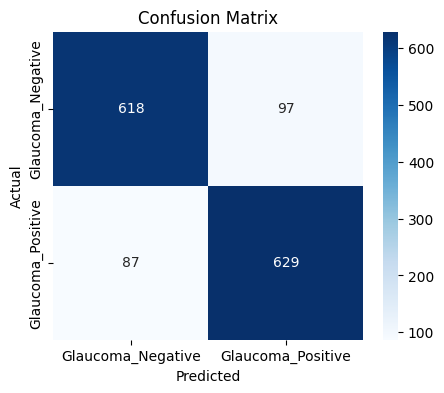

In [38]:
# Predictions
y_prob = model.predict(test_data, verbose=0).flatten()
y_pred = (y_prob >= 0.5).astype(int)
y_true = np.concatenate([y.numpy() for _, y in test_data], axis=0).astype(int).flatten()

# Class names (reuse from earlier, or hardcode)
class_names = ["Glaucoma_Negative", "Glaucoma_Positive"]

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:\n", cm)

# Classification report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

# Heatmap
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

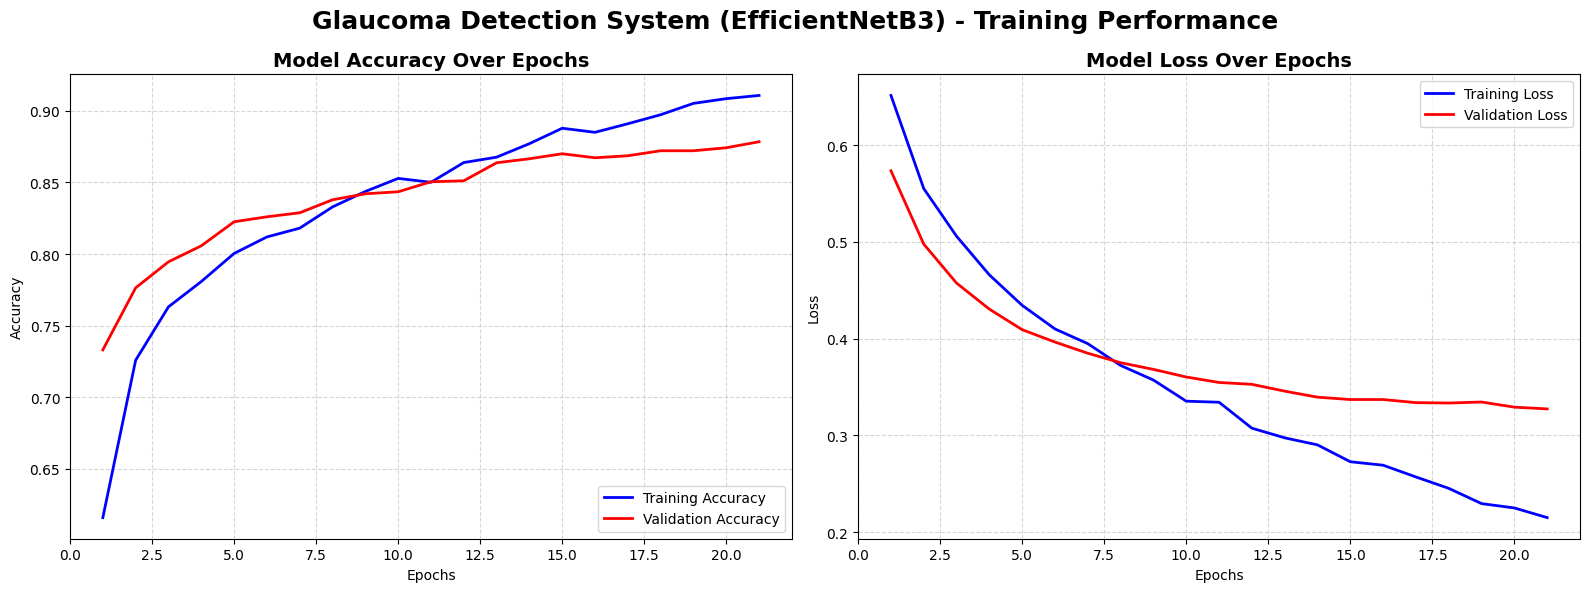

In [43]:
# Slice the history to only include up to the best epoch (Epoch 21)
best_epoch = 21

acc      = history.history['accuracy'][:best_epoch]
val_acc  = history.history['val_accuracy'][:best_epoch]
loss     = history.history['loss'][:best_epoch]
val_loss = history.history['val_loss'][:best_epoch]

epochs_range = range(1, best_epoch + 1)

plt.figure(figsize=(16, 6))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, 'b-', label='Training Accuracy', linewidth=2)
plt.plot(epochs_range, val_acc, 'r-', label='Validation Accuracy', linewidth=2)
plt.title('Model Accuracy Over Epochs', fontsize=14, fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, 'b-', label='Training Loss', linewidth=2)
plt.plot(epochs_range, val_loss, 'r-', label='Validation Loss', linewidth=2)
plt.title('Model Loss Over Epochs', fontsize=14, fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right')

plt.suptitle(
    "Glaucoma Detection System (EfficientNetB3) - Training Performance",
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

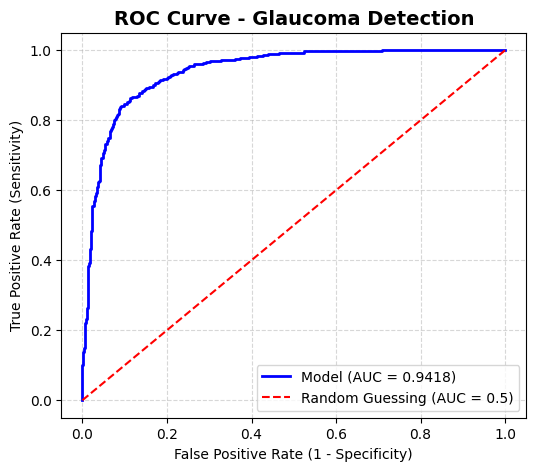

In [44]:
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate AUC
auc_score = roc_auc_score(y_true, y_prob)

# Get the curve data
fpr, tpr, thresholds = roc_curve(y_true, y_prob)

# Plot it
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='blue', linewidth=2, label=f'Model (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Random Guessing (AUC = 0.5)')

plt.title('ROC Curve - Glaucoma Detection', fontsize=14, fontweight='bold')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')
plt.show()

Please upload an image...


Saving EyePACS-TRAIN-RG-1924.jpg to EyePACS-TRAIN-RG-1924.jpg

Image selected: EyePACS-TRAIN-RG-1924.jpg


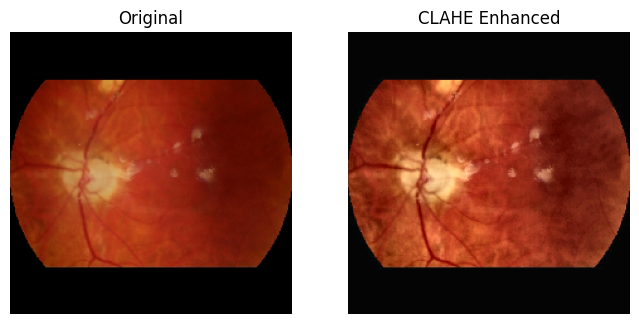

------------------------------
Raw Probability : 0.9444 (Threshold is 0.5)
🛑 Prediction: Glaucoma
------------------------------


In [81]:
from google.colab import files
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt
import cv2 # OpenCV for CLAHE

def apply_clahe(img_array):
    # Convert to uint8 for CLAHE
    img_uint8 = np.uint8(img_array)
    # Convert RGB to LAB color space
    lab = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    # Apply CLAHE to the L (lightness) channel
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    cl = clahe.apply(l)
    # Merge back and convert to RGB
    limg = cv2.merge((cl, a, b))
    final_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
    return final_img

def predict_glaucoma(model):
    print("Please upload an image...")
    uploaded = files.upload()

    for file_name in uploaded.keys():
        print(f"\nImage selected: {file_name}")

        # Load image
        img = image.load_img(file_name, target_size=(224, 224))
        img_array = image.img_to_array(img) # [0, 255]

        # Apply CLAHE to enhance contrast (helps with hazy/dark images)
        enhanced_array = apply_clahe(img_array)

        # Prepare for model
        input_array = np.expand_dims(enhanced_array, axis=0)

        # Predict
        prob = model.predict(input_array, verbose=0)[0][0]

        # Show BOTH original and enhanced image
        plt.figure(figsize=(8, 4))

        plt.subplot(1, 2, 1)
        plt.imshow(img)
        plt.title("Original")
        plt.axis('off')

        plt.subplot(1, 2, 2)
        plt.imshow(enhanced_array)
        plt.title("CLAHE Enhanced")
        plt.axis('off')
        plt.show()

        print("-" * 30)
        # Let's print the exact probability to see how close it was
        print(f"Raw Probability : {prob:.4f} (Threshold is 0.5)")

        if prob >= 0.5:
            print(f"🛑 Prediction: Glaucoma")
        else:
            print(f"✅ Prediction: Non-Glaucoma")
        print("-" * 30)

predict_glaucoma(model)

In [45]:
from google.colab import drive
drive.mount('/content/drive')

MODEL_SAVE_PATH = "/content/drive/MyDrive/glaucoma_detector_EfficientNetB3_model.h5"
model.save(MODEL_SAVE_PATH)
print(f"Model successfully saved to {MODEL_SAVE_PATH}.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model successfully saved to /content/drive/MyDrive/glaucoma_detector_EfficientNetB0_model.h5.
